# DS675 Mini Project — Part 1: data, label, features, baselines, backtest, PCA, LightGBM

**Question:** over the next 5 trading days, will a stock beat the median S&P 500 stock?

This notebook covers Milestone 2 Steps 1–3 (clean, label, features), Step 5 (walk-forward split),
Step 6 (baselines) and Step 8 (evaluation), then saves the out-of-sample predictions for every
stock and day and runs a first weekly long-short backtest with trading costs (Step 9).
Then a PCA analysis of the features and of the stocks' daily returns, and finally LightGBM
(Step 7) on the same folds, compared with logistic regression and combined into an ensemble.
The LSTM and peer-group clustering (Step 4) build on the `panel` and `folds` produced here.

Design choices that matter for leakage:
* All prices and returns use **Adj Close**; raw `Close` is only used for dollar volume (Close × Volume),
  which is split-consistent.
* The data is pivoted to wide `date × ticker` matrices on one shared trading calendar, so every
  `shift(k)` means *k trading days* for every stock, and no ticker's window can cross into another's.
* Every feature at date *t* uses prices up to and including *t* only (checked by a truncation test).
* All stocks share the same yearly cutoffs, and the last 5 days before each validation/test period
  are purged so no training label overlaps them.
* One deliberate exception: the bad-print filter in Step 1 removes a price that jumps >2x and fully
  reverses the *next* day. This is data cleaning, not a signal, and it touches very few rows (reported).

`tests/test_no_lookahead.py` rebuilds the features on data cut off at several dates and checks they
are identical to the full-data features, re-derives labels by hand, and checks the fold purges.

In [1]:
import glob
import os
import time
import warnings

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

## Configuration

In [2]:
def find_csv():
    """Env var SP500_CSV wins; otherwise look in Kaggle's input folder, then the current folder."""
    if os.environ.get("SP500_CSV"):
        return os.environ["SP500_CSV"]
    for pattern in ["/kaggle/input/**/*.csv", "./*.csv", "./data/*.csv"]:
        hits = sorted(glob.glob(pattern, recursive=True), key=os.path.getsize, reverse=True)
        if hits:
            return hits[0]  # the main file is by far the largest CSV
    raise FileNotFoundError("Set SP500_CSV or put the dataset CSV in ./ or ./data/")


DATA_PATH = find_csv()
START_DATE = pd.Timestamp("2000-01-01")   # first date that can carry a label / be evaluated
WARMUP_DAYS = 400                          # calendar days of history kept before START_DATE for 252-day features
HORIZON = 5                                # forward return horizon in trading days
MIN_STOCKS_PER_DAY = 50                    # days with fewer valid stocks get no label
EXCLUDE_TICKERS = ["CICC"]                 # removed outright (see Milestone 2, Step 1)
SPIKE_LOG_RET = np.log(2.0)                # a one-day jump of >2x that fully reverses next day = bad print
FLAG_ABS_DAILY_RET = 1.0                   # tickers with any |daily return| > 100% are reported for review
MIN_TRAIN_YEARS = 4                        # first fold trains on 2000–2003, validates 2004, tests 2005
LOGIT_C_GRID = [0.001, 0.01, 0.1, 1.0]
REFIT_ON_TRAIN_VAL = True                  # after picking C on the val year, refit on train+val (purged)
RANDOM_SEED = 675
OUT_DIR = os.environ.get("OUT_DIR", ".")
print("Data file:", DATA_PATH)

Data file: /kaggle/input/datasets/parsalatifi/s-and-p-500-us-stock-market-data/master_stock_data.csv


## Step 1 — Load and clean

In [3]:
PRICE_COLS = ["Open", "High", "Low", "Close", "Adj Close"]


def load_raw(path):
    cols = ["Date", "Ticker"] + PRICE_COLS + ["Volume"]
    df = pd.read_csv(path, usecols=cols)
    # yfinance dates can be plain or carry a UTC offset; normalise both to a naive calendar date
    df["Date"] = pd.to_datetime(df["Date"], utc=True, format="mixed").dt.tz_localize(None).dt.normalize()
    df["Ticker"] = df["Ticker"].astype(str)
    return df


def clean(raw, start=START_DATE, warmup_days=WARMUP_DAYS, exclude=EXCLUDE_TICKERS, verbose=True):
    rep = {"rows_raw": len(raw), "tickers_raw": raw["Ticker"].nunique()}
    df = raw[~raw["Ticker"].isin(exclude)].copy()
    rep["tickers_excluded"] = sorted(set(exclude) & set(raw["Ticker"].unique()))

    df = df[df["Date"] >= start - pd.Timedelta(days=warmup_days)]
    df = df.sort_values(["Ticker", "Date"])
    n0 = len(df)
    df = df.drop_duplicates(["Ticker", "Date"], keep="last")
    rep["duplicate_rows_dropped"] = n0 - len(df)

    # zero / negative prices are yfinance artefacts -> missing
    for c in PRICE_COLS:
        bad = df[c] <= 0
        rep[f"nonpositive_{c}"] = int(bad.sum())
        df.loc[bad, c] = np.nan
    df.loc[df["Volume"] <= 0, "Volume"] = np.nan

    n0 = len(df)
    df = df.dropna(subset=["Adj Close"])
    rep["rows_without_adj_close_dropped"] = n0 - len(df)

    # isolated bad prints: up >2x then straight back down (or the reverse) -> set that day's prices missing
    lp = np.log(df["Adj Close"])
    r_in = lp - lp.groupby(df["Ticker"]).shift(1)
    r_out = lp.groupby(df["Ticker"]).shift(-1) - lp
    spike = ((r_in > SPIKE_LOG_RET) & (r_out < -SPIKE_LOG_RET)) | ((r_in < -SPIKE_LOG_RET) & (r_out > SPIKE_LOG_RET))
    rep["spike_prints_removed"] = int(spike.sum())
    df = df[~spike]

    # report (not drop) tickers with extreme moves so the group can inspect them
    ret = df.groupby("Ticker")["Adj Close"].pct_change()
    extreme = df.loc[ret.abs() > FLAG_ABS_DAILY_RET, ["Ticker", "Date"]].assign(ret=ret[ret.abs() > FLAG_ABS_DAILY_RET])
    rep["flagged_extreme_moves"] = extreme

    rep["rows_clean"] = len(df)
    rep["tickers_clean"] = df["Ticker"].nunique()
    if verbose:
        for k, v in rep.items():
            if k != "flagged_extreme_moves":
                print(f"{k:32s} {v}")
        print(f"{'flagged_extreme_moves':32s} {len(extreme)} rows in {extreme['Ticker'].nunique()} tickers")
    return df.reset_index(drop=True), rep


def to_wide(df):
    """Pivot to date x ticker matrices on a shared trading calendar."""
    wide = {
        "px": df.pivot(index="Date", columns="Ticker", values="Adj Close"),
        "close": df.pivot(index="Date", columns="Ticker", values="Close"),
        "volume": df.pivot(index="Date", columns="Ticker", values="Volume"),
    }
    # drop calendar days on which only a handful of tickers report (holiday artefacts)
    n = wide["px"].notna().sum(axis=1)
    keep = n >= 0.5 * n.rolling(21, min_periods=1).median()
    for k in wide:
        wide[k] = wide[k].loc[keep].astype("float64")
    return wide

## Step 2 — Label

$y_{i,t} = 1[\,r_{i,t\to t+5} > \text{median}_j\, r_{j,t\to t+5}\,]$, using Adj Close and strict ">".

In [4]:
def make_label(px, horizon=HORIZON, min_stocks=MIN_STOCKS_PER_DAY):
    fwd = px.shift(-horizon) / px - 1.0
    med = fwd.median(axis=1)
    y = fwd.gt(med, axis=0).astype("float64")
    valid = fwd.notna() & (fwd.notna().sum(axis=1) >= min_stocks).to_numpy()[:, None]
    return fwd.where(valid), y.where(valid)

## Step 3 — Features (past data only), then cross-sectional ranks

In [5]:
def _ema(x, span):
    return x.ewm(span=span, adjust=False, min_periods=span).mean()


def make_raw_features(w):
    px, close, vol = w["px"], w["close"], w["volume"]
    lr = np.log(px).diff()
    f = {}
    for k in (1, 5, 21, 63):
        f[f"ret_{k}"] = px / px.shift(k) - 1
    f["mom_12_1"] = px.shift(21) / px.shift(252) - 1            # classic 12-month momentum skipping last month
    f["vol_21"] = lr.rolling(21, min_periods=15).std()
    f["vol_63"] = lr.rolling(63, min_periods=45).std()
    f["vol_ratio"] = f["vol_21"] / f["vol_63"]
    f["max_ret_21"] = lr.rolling(21, min_periods=15).max()      # "lottery" effect
    f["volume_ratio"] = vol / vol.rolling(20, min_periods=15).mean()
    f["dollar_vol_20"] = np.log(close * vol).rolling(20, min_periods=15).mean()  # size / liquidity proxy
    delta = px.diff()
    gain = delta.clip(lower=0).ewm(alpha=1 / 14, adjust=False, min_periods=14).mean()
    loss = (-delta.clip(upper=0)).ewm(alpha=1 / 14, adjust=False, min_periods=14).mean()
    f["rsi_14"] = 100 - 100 / (1 + gain / loss)
    macd = _ema(px, 12) - _ema(px, 26)
    f["macd"] = macd / px
    f["macd_hist"] = (macd - _ema(macd, 9)) / px
    ma20, sd20 = px.rolling(20, min_periods=20).mean(), px.rolling(20, min_periods=20).std()
    f["bb_pctb"] = (px - ma20) / (2 * sd20)
    f["dist_52w_high"] = px / px.rolling(252, min_periods=126).max() - 1
    alive = px.notna()
    return {k: v.replace([np.inf, -np.inf], np.nan).where(alive) for k, v in f.items()}


def cross_sectional_rank(x):
    """0 = lowest stock that day, 1 = highest; NaN stays NaN."""
    r = x.rank(axis=1, method="average")
    n = x.notna().sum(axis=1)
    return r.sub(1, axis=0).div((n - 1).where(n > 1), axis=0)


FEATURES = [
    "ret_1", "ret_5", "ret_21", "ret_63", "mom_12_1", "vol_21", "vol_63", "vol_ratio",
    "max_ret_21", "volume_ratio", "dollar_vol_20", "rsi_14", "macd", "macd_hist", "bb_pctb", "dist_52w_high",
]


def build_panel(w, start=START_DATE, horizon=HORIZON):
    """Long table: one row per (date, ticker) with a label, the forward return and ranked features."""
    fwd, y = make_label(w["px"], horizon)
    raw = make_raw_features(w)
    ranked = {k: cross_sectional_rank(raw[k]) for k in FEATURES}

    dates, tickers = w["px"].index, w["px"].columns
    mask = (y.notna() & (dates >= start)[:, None]).to_numpy()
    di, ti = np.nonzero(mask)
    panel = pd.DataFrame({
        "date": dates[di], "ticker": tickers[ti], "date_idx": di,
        "y": y.to_numpy()[di, ti].astype("int8"), "fwd_ret": fwd.to_numpy()[di, ti],
    })
    for k in FEATURES:
        panel[k] = ranked[k].to_numpy()[di, ti].astype("float32")
    panel["year"] = panel["date"].dt.year
    return panel

## Step 5 — Walk-forward folds (shared yearly cutoffs, 5-day purge)

In [6]:
def walk_forward_folds(panel, min_train_years=MIN_TRAIN_YEARS, horizon=HORIZON):
    years = sorted(panel["year"].unique())
    first_idx = panel.groupby("year")["date_idx"].min()
    folds = []
    for test_year in years[min_train_years + 1:]:
        val_year = test_year - 1
        if val_year not in first_idx.index:
            continue
        val_start, test_start = first_idx[val_year], first_idx[test_year]
        # a label at t looks at t+horizon, so it must end strictly before the next period starts
        tr = (panel["year"] < val_year) & (panel["date_idx"] + horizon < val_start)
        va = (panel["year"] == val_year) & (panel["date_idx"] + horizon < test_start)
        trva = (panel["year"] < test_year) & (panel["date_idx"] + horizon < test_start)
        te = panel["year"] == test_year
        folds.append({"test_year": test_year, "train": tr.to_numpy(), "val": va.to_numpy(),
                      "train_val": trva.to_numpy(), "test": te.to_numpy()})
    return folds

## Step 6 — Baselines, Step 8 — metrics

In [7]:
def daily_ic(dates, score, fwd):
    """Mean over days of the Spearman correlation between score and forward return."""
    d = pd.DataFrame({"d": dates, "s": score, "f": fwd})
    g = d.groupby("d")
    rs = g["s"].rank() - g["s"].transform("size").add(1) / 2
    rf = g["f"].rank() - g["f"].transform("size").add(1) / 2
    num = (rs * rf).groupby(d["d"]).sum()
    den = np.sqrt((rs ** 2).groupby(d["d"]).sum() * (rf ** 2).groupby(d["d"]).sum())
    return (num / den).dropna()


def evaluate(part, score, horizon=HORIZON):
    d = part[["date", "y", "fwd_ret"]].copy()
    d["s"] = score
    g = d.groupby("date")["s"]
    pred = (d["s"] > g.transform("median")).astype(int)        # top half of each day -> predict 1
    ic = daily_ic(d["date"], d["s"], d["fwd_ret"])
    ic_nonoverlap = ic.iloc[::horizon]
    q = g.rank(pct=True)
    spread = d.loc[q > 0.9].groupby("date")["fwd_ret"].mean() - d.loc[q <= 0.1].groupby("date")["fwd_ret"].mean()
    return {
        "accuracy": (pred == d["y"]).mean(),
        "auc": roc_auc_score(d["y"], d["s"]),
        "ic_mean": ic.mean(),
        "ic_tstat": ic_nonoverlap.mean() / ic_nonoverlap.std() * np.sqrt(len(ic_nonoverlap)),
        "top_minus_bottom_decile_5d_bps": spread.mean() * 1e4,
        "n_rows": len(d),
    }


def X_of(df):
    return (df[FEATURES].fillna(0.5) - 0.5).to_numpy(dtype="float32")


def fit_logit(train, C):
    m = LogisticRegression(C=C, max_iter=300)
    return m.fit(X_of(train), train["y"].to_numpy())


def run_baselines(panel, folds, verbose=True):
    rng = np.random.default_rng(RANDOM_SEED)
    rows, chosen = [], []
    for f in folds:
        t0 = time.time()
        test = panel[f["test"]]
        scores = {
            "random": rng.random(len(test)),
            "momentum_12_1": test["mom_12_1"].fillna(0.5).to_numpy(),
            "momentum_1m": test["ret_21"].fillna(0.5).to_numpy(),
            "reversal_1w": 1 - test["ret_5"].fillna(0.5).to_numpy(),
        }
        train, val = panel[f["train"]], panel[f["val"]]
        best_C = max(LOGIT_C_GRID, key=lambda C: roc_auc_score(
            val["y"], fit_logit(train, C).predict_proba(X_of(val))[:, 1]))
        final = fit_logit(panel[f["train_val"]] if REFIT_ON_TRAIN_VAL else train, best_C)
        scores["logistic"] = final.predict_proba(X_of(test))[:, 1]
        chosen.append({"test_year": f["test_year"], "C": best_C, "coef": dict(zip(FEATURES, final.coef_[0]))})
        for name, s in scores.items():
            rows.append({"test_year": f["test_year"], "model": name, **evaluate(test, s)})
        if verbose:
            print(f"test {f['test_year']}: train {f['train'].sum():>9,d}  val {f['val'].sum():>7,d}  "
                  f"test {f['test'].sum():>7,d}  C={best_C:<6}  {time.time() - t0:5.1f}s")
    return pd.DataFrame(rows), chosen


def summarise(results):
    agg = results.groupby("model").agg(
        accuracy=("accuracy", "mean"), auc=("auc", "mean"), ic_mean=("ic_mean", "mean"),
        years_ic_positive=("ic_mean", lambda s: f"{(s > 0).sum()}/{len(s)}"),
        decile_spread_5d_bps=("top_minus_bottom_decile_5d_bps", "mean"),
    )
    # t-stat of the yearly mean IC across years (years are non-overlapping)
    t = results.groupby("model")["ic_mean"].agg(lambda s: s.mean() / s.std() * np.sqrt(len(s)))
    agg.insert(3, "ic_tstat_across_years", t)
    return agg.sort_values("auc", ascending=False)

## Run Steps 1–3

In [8]:
t0 = time.time()
raw = load_raw(DATA_PATH)
print(f"loaded {len(raw):,} rows in {time.time() - t0:.1f}s")
df, clean_report = clean(raw)
del raw
clean_report["flagged_extreme_moves"].groupby("Ticker").size().sort_values(ascending=False).head(15)

loaded 2,219,678 rows in 4.2s
rows_raw                         2219678
tickers_raw                      233
tickers_excluded                 ['CICC']
duplicate_rows_dropped           0
nonpositive_Open                 0
nonpositive_High                 0
nonpositive_Low                  0
nonpositive_Close                0
nonpositive_Adj Close            0
rows_without_adj_close_dropped   4
spike_prints_removed             0
rows_clean                       1461861
tickers_clean                    232
flagged_extreme_moves            2 rows in 2 tickers


Ticker
HIG    1
WMB    1
dtype: int64

In [9]:
wide = to_wide(df)
panel = build_panel(wide)
print(f"panel: {len(panel):,} rows, {panel['ticker'].nunique()} tickers, "
      f"{panel['date'].min().date()} to {panel['date'].max().date()}")
per_day = panel.groupby("date").size()
print(f"stocks per day: min {per_day.min()}, median {per_day.median():.0f}, max {per_day.max()}")
print(f"label balance: {panel['y'].mean():.4f}  (≈0.5 by construction, slightly below because of strict '>')")
panel[FEATURES].describe().T[["count", "mean", "min", "max"]]

panel: 1,413,301 rows, 231 tickers, 2000-01-03 to 2026-08-21
stocks per day: min 175, median 217, max 231
label balance: 0.4988  (≈0.5 by construction, slightly below because of strict '>')


,count,mean,min,max
ret_1,1413245.0,0.5,0.0,1.0
ret_5,1413021.0,0.5,0.0,1.0
ret_21,1412125.0,0.5,0.0,1.0
ret_63,1409713.0,0.5,0.0,1.0
mom_12_1,1398407.0,0.5,0.0,1.0
vol_21,1412461.0,0.5,0.0,1.0
vol_63,1410757.0,0.5,0.0,1.0
vol_ratio,1410757.0,0.5,0.0,1.0
max_ret_21,1412461.0,0.5,0.0,1.0
volume_ratio,1412458.0,0.5,0.0,1.0


Feature coverage and rank IC of each feature on its own (full sample, *descriptive only*;
model selection uses the walk-forward folds below).

In [10]:
feat_ic = pd.DataFrame({
    k: {"coverage": panel[k].notna().mean(),
        "ic_mean": daily_ic(panel["date"], panel[k].fillna(0.5), panel["fwd_ret"]).mean()}
    for k in FEATURES}).T
feat_ic.sort_values("ic_mean")

,coverage,ic_mean
ret_5,0.999802,-0.023869
bb_pctb,0.999247,-0.020726
rsi_14,0.999445,-0.020538
dollar_vol_20,0.999425,-0.019782
ret_1,0.999960,-0.018258
macd_hist,0.998690,-0.016685
ret_21,0.999168,-0.016311
dist_52w_high,0.994874,-0.016114
macd,0.999009,-0.015795
ret_63,0.997461,-0.014058


## Steps 5–8 — Walk-forward baselines

In [11]:
folds = walk_forward_folds(panel)
print(f"{len(folds)} folds: test years {folds[0]['test_year']}–{folds[-1]['test_year']}")
results, logit_fits = run_baselines(panel, folds)

22 folds: test years 2005–2026
test 2005: train   181,974  val  46,191  test  48,337  C=1.0       2.5s
test 2006: train   229,095  val  47,362  test  49,534  C=1.0       3.1s
test 2007: train   277,407  val  48,544  test  50,015  C=1.0       2.8s
test 2008: train   326,926  val  49,015  test  51,002  C=0.001     3.0s
test 2009: train   376,931  val  49,992  test  51,070  C=0.001     3.2s
test 2010: train   427,923  val  50,045  test  52,041  C=0.001     3.9s
test 2011: train   478,978  val  51,006  test  52,726  C=1.0       4.5s
test 2012: train   531,009  val  51,676  test  53,127  C=1.0       3.8s
test 2013: train   583,720  val  52,052  test  54,840  C=0.01      4.2s
test 2014: train   636,822  val  53,745  test  55,509  C=0.001     4.9s
test 2015: train   691,642  val  54,399  test  55,944  C=1.0       5.7s
test 2016: train   747,136  val  54,834  test  55,944  C=1.0       5.8s
test 2017: train   803,080  val  54,834  test  55,883  C=0.001     6.6s
test 2018: train   859,024  val  

In [12]:
summary = summarise(results)
summary

,accuracy,auc,ic_mean,ic_tstat_across_years,years_ic_positive,decile_spread_5d_bps
model,,,,,,
logistic,0.510636,0.514894,0.029983,10.575740,22/22,37.249645
reversal_1w,0.506618,0.508987,0.019860,6.930337,20/22,25.095303
momentum_12_1,0.505258,0.507346,0.012380,1.883577,16/22,-3.581987
random,0.499417,0.499326,-0.002114,-1.990717,7/22,-5.093899
momentum_1m,0.497077,0.495127,-0.011861,-3.303768,4/22,-10.616000


In [13]:
results.pivot(index="test_year", columns="model", values="auc").round(4)

model,logistic,momentum_12_1,momentum_1m,random,reversal_1w
test_year,,,,,
2005,0.5160,0.5310,0.5026,0.5017,0.5065
2006,0.5077,0.4893,0.4974,0.5009,0.5148
2007,0.5135,0.5271,0.4926,0.4974,0.5225
2008,0.5226,0.5042,0.4813,0.5003,0.5183
2009,0.5221,0.4820,0.4857,0.4958,0.5144
2010,0.5215,0.5024,0.4921,0.4975,0.5072
2011,0.5158,0.5072,0.4952,0.5025,0.5160
2012,0.5047,0.5111,0.5085,0.4995,0.4946
2013,0.5262,0.5188,0.4903,0.5038,0.5189


In [14]:
coef = pd.DataFrame({c["test_year"]: c["coef"] for c in logit_fits}).T
print("Logistic coefficients (feature ranks centred at 0), last 5 folds:")
coef.tail(5).T.round(3)

Logistic coefficients (feature ranks centred at 0), last 5 folds:


,2022,2023,2024,2025,2026
ret_1,-0.093,-0.094,-0.076,-0.096,-0.093
ret_5,-0.115,-0.125,-0.102,-0.108,-0.102
ret_21,0.065,0.090,0.027,0.045,0.036
ret_63,-0.023,-0.031,-0.055,-0.052,-0.061
mom_12_1,0.104,0.112,0.104,0.125,0.124
vol_21,-0.035,-0.050,-0.002,-0.023,-0.024
vol_63,0.068,0.076,0.041,0.057,0.076
vol_ratio,0.021,0.018,0.001,0.014,0.015
max_ret_21,0.017,0.025,0.029,0.026,0.028
volume_ratio,0.058,0.058,0.054,0.060,0.059


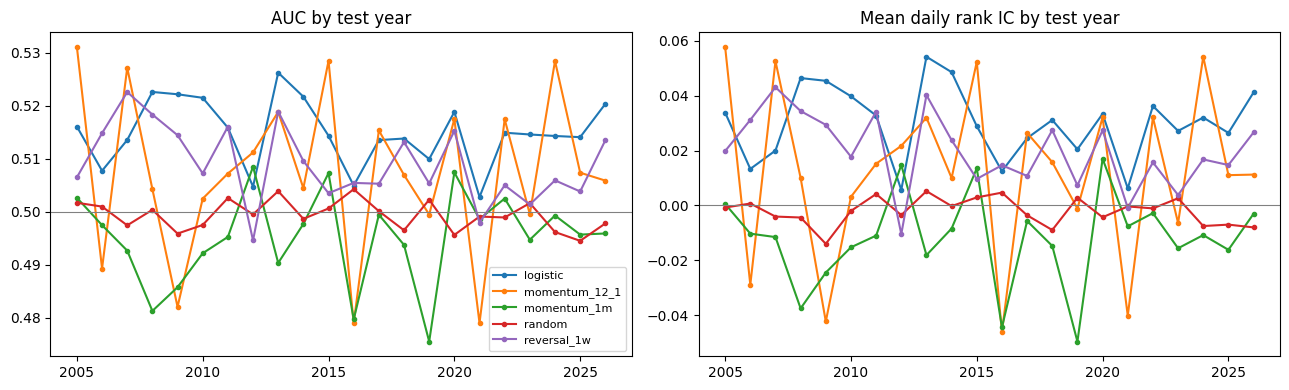

In [15]:
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for m, g in results.groupby("model"):
        ax[0].plot(g["test_year"], g["auc"], marker="o", ms=3, label=m)
        ax[1].plot(g["test_year"], g["ic_mean"], marker="o", ms=3, label=m)
    ax[0].axhline(0.5, color="grey", lw=0.8); ax[1].axhline(0, color="grey", lw=0.8)
    ax[0].set_title("AUC by test year"); ax[1].set_title("Mean daily rank IC by test year")
    ax[0].legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "baselines_by_year.png"), dpi=120)
    plt.show()
except ImportError:
    pass

In [16]:
os.makedirs(OUT_DIR, exist_ok=True)
results.to_csv(os.path.join(OUT_DIR, "baseline_results_by_year.csv"), index=False)
summary.to_csv(os.path.join(OUT_DIR, "baseline_summary.csv"))
panel.to_parquet(os.path.join(OUT_DIR, "panel.parquet")) if os.environ.get("SAVE_PANEL") else None
print("saved results to", os.path.abspath(OUT_DIR))

saved results to /kaggle/working


## Predicting the past: out-of-sample predictions and a backtest

Every prediction below comes from a model trained only on years *before* the year it predicts
(the same walk-forward folds as above), so this is an honest replay of history.
Never train on all years and then predict those same years: that model has already seen the answers.

In [17]:
def oos_predictions(panel, folds, logit_fits):
    """Refit each fold's logistic model (same C as chosen above) and keep its test-year predictions."""
    out = []
    for f, fit in zip(folds, logit_fits):
        train = panel[f["train_val"]] if REFIT_ON_TRAIN_VAL else panel[f["train"]]
        model = fit_logit(train, fit["C"])
        test = panel.loc[f["test"], ["date", "ticker", "y", "fwd_ret"]].copy()
        test["prob_beat_median"] = model.predict_proba(X_of(panel[f["test"]]))[:, 1]
        out.append(test)
    preds = pd.concat(out, ignore_index=True)
    g = preds.groupby("date")["prob_beat_median"]
    preds["rank_pct"] = g.rank(pct=True)                       # 1 = model's favourite stock that day
    preds["predicted_y"] = (preds["prob_beat_median"] > g.transform("median")).astype(int)
    preds["correct"] = (preds["predicted_y"] == preds["y"]).astype(int)
    return preds


t0 = time.time()
preds = oos_predictions(panel, folds, logit_fits)
print(f"{len(preds):,} out-of-sample predictions, {preds['date'].min().date()} to {preds['date'].max().date()} "
      f"({time.time() - t0:.0f}s); overall hit rate {preds['correct'].mean():.4f}")
preds.to_csv(os.path.join(OUT_DIR, "oos_predictions.csv.gz"), index=False)
preds.head()

1,183,256 out-of-sample predictions, 2005-01-03 to 2026-08-21 (25s); overall hit rate 0.5105


,date,ticker,y,fwd_ret,prob_beat_median,rank_pct,predicted_y,correct
0,2005-01-03,A,0,-0.053602,0.519093,0.742105,1,0
1,2005-01-03,AAPL,1,0.089588,0.442124,0.021053,0,0
2,2005-01-03,ABT,1,0.027641,0.436991,0.005263,0,0
3,2005-01-03,ACN,1,0.022374,0.523691,0.784211,1,1
4,2005-01-03,ADI,0,-0.026931,0.500800,0.531579,1,0


### Look up one stock
`y` = what actually happened (1 = beat the median over the next 5 days),
`predicted_y` = the model's call, `fwd_ret` = the stock's actual 5-day return.

In [18]:
TICKER, FROM, TO = "AAPL", "2020-02-15", "2022-04-15"   # change the ticker and dates here
if TICKER not in set(preds["ticker"]):
    print(f"{TICKER} not in the data; using {preds['ticker'].iloc[0]} instead")
    TICKER = preds["ticker"].iloc[0]
preds[(preds["ticker"] == TICKER) & preds["date"].between(FROM, TO)][
    ["date", "ticker", "prob_beat_median", "rank_pct", "predicted_y", "y", "fwd_ret", "correct"]]

,date,ticker,prob_beat_median,rank_pct,predicted_y,y,fwd_ret,correct
805796,2020-02-18,AAPL,0.512320,0.775330,1,0,-0.096928,0
806023,2020-02-19,AAPL,0.482313,0.171806,0,0,-0.095699,1
806250,2020-02-20,AAPL,0.502702,0.616740,1,0,-0.146051,0
806477,2020-02-21,AAPL,0.507866,0.678414,1,0,-0.126785,0
806704,2020-02-24,AAPL,0.513710,0.775330,1,1,0.002113,1
...,...,...,...,...,...,...,...,...
930081,2022-04-08,AAPL,0.492965,0.411255,0,0,-0.029514,1
930312,2022-04-11,AAPL,0.501576,0.575758,1,0,0.009955,0
930543,2022-04-12,AAPL,0.492188,0.406926,0,0,-0.002565,1
930774,2022-04-13,AAPL,0.491139,0.337662,0,0,-0.023357,1


In [19]:
# Which stocks did the model call best and worst on one day?
DAY = preds["date"].iloc[len(preds) // 2]
day = preds[preds["date"] == DAY].sort_values("prob_beat_median", ascending=False)
print(f"{DAY.date()}: model's top 5 and bottom 5, with what actually happened over the next 5 days")
pd.concat([day.head(5), day.tail(5)])[["ticker", "prob_beat_median", "fwd_ret", "y"]]

2016-04-26: model's top 5 and bottom 5, with what actually happened over the next 5 days


,ticker,prob_beat_median,fwd_ret,y
591663,TTWO,0.565942,-0.027778,0
591627,PGR,0.549288,0.013130,1
591577,KMB,0.547281,0.018738,1
591609,NFLX,0.547004,-0.009629,1
591679,XEL,0.541762,0.034703,1
591521,CVX,0.453608,-0.009483,1
591677,WMB,0.451711,0.000000,1
591499,C,0.451321,-0.031461,0
591532,DVN,0.450943,-0.054015,0
591620,OXY,0.450653,-0.011898,1


In [20]:
by_ticker = preds.groupby("ticker").agg(days=("correct", "size"), hit_rate=("correct", "mean"))
print("Hit rate per stock (all should hover near 0.5; the edge is small and spread across many stocks):")
by_ticker.describe().T

Hit rate per stock (all should hover near 0.5; the edge is small and spread across many stocks):


,count,mean,std,min,25%,50%,75%,max
days,231.0,5122.320346,865.945239,1152.000000,5443.000000,5443.00000,5443.000000,5443.000000
hit_rate,231.0,0.510357,0.013702,0.465185,0.501929,0.51038,0.519015,0.547477


### Check the labels for the looked-up stock against the median stock
For each day: the stock's actual 5-day return, the median stock's 5-day return, and whether the stock
beat it. `labels match recomputation` must be True (it re-derives `y` from the returns).

In [21]:
a = preds[(preds["ticker"] == TICKER) & preds["date"].between(FROM, TO)].copy()
med = preds.groupby("date")["fwd_ret"].median()
a["median_stock_5d"] = a["date"].map(med)
a["beat_median_check"] = (a["fwd_ret"] > a["median_stock_5d"]).astype(int)
print(f"{TICKER} {FROM} to {TO}: {len(a)} days, model right {a['correct'].mean():.1%}; "
      f"labels match recomputation: {(a['beat_median_check'] == a['y']).all()}")
a[["date", "rank_pct", "predicted_y", "fwd_ret", "median_stock_5d", "y", "correct"]]

AAPL 2020-02-15 to 2022-04-15: 546 days, model right 49.8%; labels match recomputation: True


,date,rank_pct,predicted_y,fwd_ret,median_stock_5d,y,correct
805796,2020-02-18,0.775330,1,-0.096928,-0.071406,0,0
806023,2020-02-19,0.171806,0,-0.095699,-0.083601,0,1
806250,2020-02-20,0.616740,1,-0.146051,-0.117542,0,0
806477,2020-02-21,0.678414,1,-0.126785,-0.118075,0,0
806704,2020-02-24,0.775330,1,0.002113,-0.051794,1,1
...,...,...,...,...,...,...,...
930081,2022-04-08,0.411255,0,-0.029514,-0.011090,0,1
930312,2022-04-11,0.575758,1,0.009955,0.013212,0,0
930543,2022-04-12,0.406926,0,-0.002565,0.026243,0,1
930774,2022-04-13,0.337662,0,-0.023357,0.001477,0,1


### Is the model more accurate when it is more confident about this stock?
Days are grouped by where the model ranked the stock that day. For one stock the groups are small,
so read this with care (each label covers 5 days, so 100 days is only about 20 independent calls).

In [22]:
a["confidence"] = pd.cut(a["rank_pct"], [0, 0.2, 0.4, 0.6, 0.8, 1.0],
                         labels=["strong lag", "lag", "neutral", "beat", "strong beat"])
print(a.groupby("confidence", observed=True).agg(days=("correct", "size"),
                                                  hit_rate=("correct", "mean")).round(3))
print(f"\n{TICKER} actually beat the median on {a['y'].mean():.1%} of these days")
print(f"{TICKER} hit rate 2005–2026: {by_ticker.loc[TICKER, 'hit_rate']:.3f} "
      f"(average stock {by_ticker['hit_rate'].mean():.3f})")

             days  hit_rate
confidence                 
strong lag    230     0.509
lag           129     0.543
neutral        83     0.446
beat           68     0.441
strong beat    36     0.500

AAPL actually beat the median on 46.7% of these days
AAPL hit rate 2005–2026: 0.465 (average stock 0.510)


### Which stocks does the model get most and least right?
With 231 stocks, the extremes are expected to be spread out by chance alone: about ±1.5 points per stock
(each stock has roughly 1,100 independent 5-day periods), and with 231 stocks one landing ~3 standard
deviations from the average happens by luck roughly a quarter of the time.

In [23]:
ranked = by_ticker.sort_values("hit_rate")
print(f"hit-rate spread across stocks: {by_ticker['hit_rate'].std():.4f} "
      f"(chance alone ≈ {np.sqrt(0.25 / (by_ticker['days'].median() / HORIZON)):.4f})")
pd.concat({"worst 10": ranked.head(10).reset_index(), "best 10": ranked.tail(10)[::-1].reset_index()},
          axis=1).round(3)

hit-rate spread across stocks: 0.0137 (chance alone ≈ 0.0152)


worst 10                best 10               
    ticker  days hit_rate  ticker  days hit_rate
0     AAPL  5443    0.465     HLT  3191    0.547
1      DOW  1867    0.469    ANET  3071    0.543
2      HAL  5443    0.477    FTNT  4214    0.542
3      HSY  5443    0.479     EMR  5443    0.540
4      LVS  5443    0.480     CNC  5443    0.538
5     DLTR  5443    0.483     USB  5443    0.538
6      CAT  5443    0.484     TDG  5142    0.538
7     TSLA  4062    0.484     LIN  5443    0.537
8    GOOGL  5443    0.484     STZ  5443    0.536
9      NEE  5443    0.486    MPWR  5443    0.535

### Does accuracy depend on company size?
Stocks are split into five equal groups by their dollar-volume rank that day (a size/liquidity proxy).
`model_said_beat` vs `actually_beat` shows the model's size tilt: it favours small stocks much more
than the data justifies. Accuracy is still flat across groups, but the backtest's long-short
portfolio inherits this tilt (long small, short large).

In [24]:
x = preds.merge(panel[["date", "ticker", "dollar_vol_20"]], on=["date", "ticker"])
x["size"] = pd.qcut(x["dollar_vol_20"], 5, labels=["smallest", "small", "mid", "large", "largest"])
x.groupby("size", observed=True).agg(hit_rate=("correct", "mean"),
                                     actually_beat=("y", "mean"),
                                     model_said_beat=("predicted_y", "mean")).round(3)

,hit_rate,actually_beat,model_said_beat
size,,,
smallest,0.512,0.511,0.776
small,0.510,0.502,0.629
mid,0.508,0.497,0.486
large,0.510,0.494,0.354
largest,0.513,0.491,0.247


### Backtest (Milestone Step 9, first version)
Every 5th trading day: buy the model's top 10% (equal weight), short its bottom 10%, hold 5 days.
Trading cost: 0.10% of every dollar traded. Also shown: long-only top 10%, and the equal-weight
average of all stocks as a benchmark. Returns use Adj Close, so dividends are included.

In [25]:
COST_PER_TRADE = 0.001
DECILE = 0.10


def backtest(preds, decile=DECILE, cost=COST_PER_TRADE, step=HORIZON):
    rebal_dates = np.sort(preds["date"].unique())[::step]      # non-overlapping 5-day holding periods
    prev_long, prev_short, rows = pd.Series(dtype=float), pd.Series(dtype=float), []
    for d in rebal_dates:
        day = preds[preds["date"] == d].dropna(subset=["fwd_ret"])
        q = day["prob_beat_median"].rank(pct=True)
        long_, short_ = day[q > 1 - decile], day[q <= decile]
        w_long = pd.Series(1 / len(long_), index=long_["ticker"].to_numpy())
        w_short = pd.Series(1 / len(short_), index=short_["ticker"].to_numpy())
        # dollars traded = how much the weights changed since last period (sells + buys)
        t_long = w_long.sub(prev_long, fill_value=0).abs().sum()
        t_short = w_short.sub(prev_short, fill_value=0).abs().sum()
        r_long, r_short = long_["fwd_ret"].mean(), short_["fwd_ret"].mean()
        rows.append({
            "date": pd.Timestamp(d),
            "long_short_gross": r_long - r_short,
            "long_short_net": r_long - r_short - cost * (t_long + t_short),
            "long_only_net": r_long - cost * t_long,
            "all_stocks": day["fwd_ret"].mean(),
            "turnover": (t_long + t_short) / 4,                 # share of the book replaced, 0..1
        })
        prev_long, prev_short = w_long, w_short
    return pd.DataFrame(rows).set_index("date")


def perf(r, periods_per_year=252 / HORIZON):
    ann_ret = (1 + r).prod() ** (periods_per_year / len(r)) - 1
    ann_vol = r.std() * np.sqrt(periods_per_year)
    wealth = (1 + r).cumprod()
    return pd.Series({"annual_return": ann_ret, "annual_vol": ann_vol,
                      "sharpe": r.mean() / r.std() * np.sqrt(periods_per_year),
                      "max_drawdown": (wealth / wealth.cummax() - 1).min(),
                      "weeks_positive": (r > 0).mean()})


bt = backtest(preds)
strategies = ["long_short_gross", "long_short_net", "long_only_net", "all_stocks"]
print(f"{len(bt)} weekly periods; average turnover {bt['turnover'].mean():.0%} of the book per week")
pd.DataFrame({s: perf(bt[s]) for s in strategies}).T.round(3)

1089 weekly periods; average turnover 63% of the book per week


,annual_return,annual_vol,sharpe,max_drawdown,weeks_positive
long_short_gross,0.166,0.195,0.887,-0.429,0.582
long_short_net,0.026,0.195,0.229,-0.554,0.521
long_only_net,0.225,0.256,0.923,-0.512,0.595
all_stocks,0.169,0.183,0.945,-0.494,0.601


In [26]:
yearly = bt[strategies].groupby(bt.index.year).apply(lambda x: (1 + x).prod() - 1)
yearly.round(3)

,long_short_gross,long_short_net,long_only_net,all_stocks
date,,,,
2005,0.212,0.074,0.371,0.230
2006,0.285,0.146,0.263,0.158
2007,0.049,-0.075,0.150,0.126
2008,0.768,0.543,-0.152,-0.290
2009,0.317,0.153,0.601,0.479
2010,0.256,0.099,0.291,0.246
2011,0.144,0.011,0.053,0.056
2012,0.062,-0.070,0.186,0.225
2013,0.464,0.280,0.672,0.384


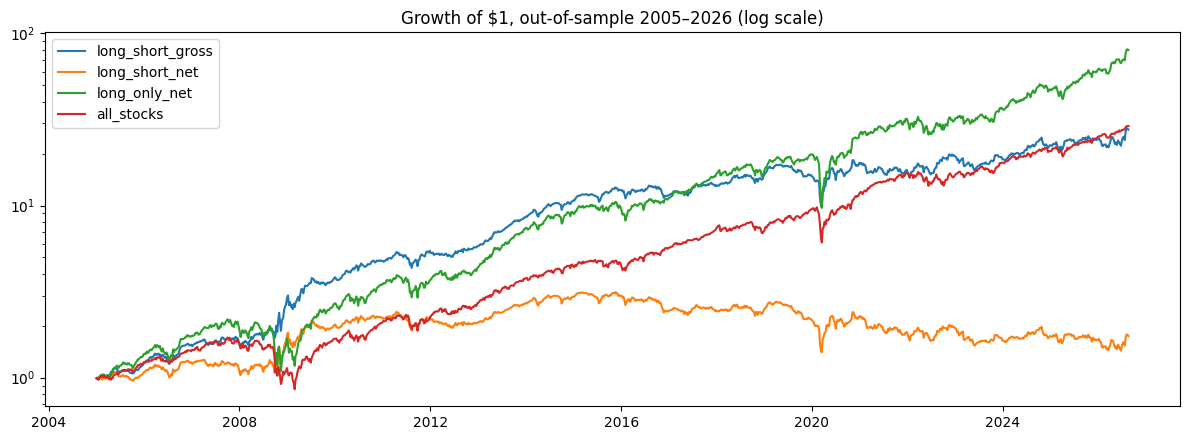

In [27]:
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(12, 4.5))
    for s in strategies:
        ax.plot((1 + bt[s]).cumprod(), label=s)
    ax.set_yscale("log"); ax.set_title("Growth of $1, out-of-sample 2005–2026 (log scale)")
    ax.legend(); plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "backtest_growth.png"), dpi=120)
    plt.show()
except ImportError:
    pass

bt.to_csv(os.path.join(OUT_DIR, "backtest_weekly.csv"))

## PCA — Principal Component Analysis

PCA rewrites a set of correlated variables as new, uncorrelated variables ("principal components",
PC1, PC2, ...), ordered by how much of the total variation each one explains. It answers
"how many independent things are really going on here, and what are they?"

We use it twice:
* **A. On the 16 features** — they overlap heavily (RSI, Bollinger %B, MACD and recent returns all
  measure "has the stock been rising?"). PCA shows how many independent signals the model really has,
  explains why individual logistic coefficients are hard to interpret, and tests whether a model on a
  few components predicts as well as one on all 16.
* **B. On daily stock returns** — PC1 is the whole market moving together; the next components are
  sector-like groups (e.g. energy vs. tech). This is the hidden structure behind the sector bets we saw
  on 2016-04-26, and the basis for the Step 4 peer groups, since the dataset has no sector column.

In [28]:
from sklearn.decomposition import PCA

### A. PCA on the 16 features (descriptive, full sample)

In [29]:
Xf = panel[FEATURES].fillna(0.5).to_numpy("float64")
Xf = (Xf - Xf.mean(0)) / Xf.std(0)
pca_f = PCA().fit(Xf)
pc_names = [f"PC{i + 1}" for i in range(len(FEATURES))]
feat_var = pd.DataFrame({"explained": pca_f.explained_variance_ratio_,
                         "cumulative": pca_f.explained_variance_ratio_.cumsum()}, index=pc_names)
for share in (0.8, 0.9):
    print(f"components needed for {share:.0%} of the variation in 16 features: "
          f"{int((feat_var['cumulative'] < share).sum()) + 1}")
feat_var.round(3)

components needed for 80% of the variation in 16 features: 6
components needed for 90% of the variation in 16 features: 8


,explained,cumulative
PC1,0.314,0.314
PC2,0.181,0.495
PC3,0.109,0.603
PC4,0.074,0.677
PC5,0.065,0.742
PC6,0.062,0.804
PC7,0.059,0.863
PC8,0.049,0.913
PC9,0.027,0.939
PC10,0.015,0.954


In [30]:
print("Loadings: how much each feature contributes to each component (sign only matters within a column)")
feat_load = pd.DataFrame(pca_f.components_[:5].T, index=FEATURES, columns=pc_names[:5])
feat_load.round(2)

Loadings: how much each feature contributes to each component (sign only matters within a column)


,PC1,PC2,PC3,PC4,PC5
ret_1,0.15,0.03,-0.24,0.41,0.42
ret_5,0.30,0.08,-0.32,0.23,0.11
ret_21,0.39,0.07,0.05,-0.22,-0.12
ret_63,0.29,-0.06,0.43,-0.06,0.08
mom_12_1,0.07,-0.12,0.44,0.40,0.26
vol_21,-0.05,0.55,0.16,0.11,0.06
vol_63,-0.04,0.50,0.11,-0.20,0.32
vol_ratio,-0.03,0.22,0.12,0.57,-0.46
max_ret_21,0.09,0.51,0.16,0.01,-0.02
volume_ratio,-0.01,-0.07,-0.03,0.12,0.48


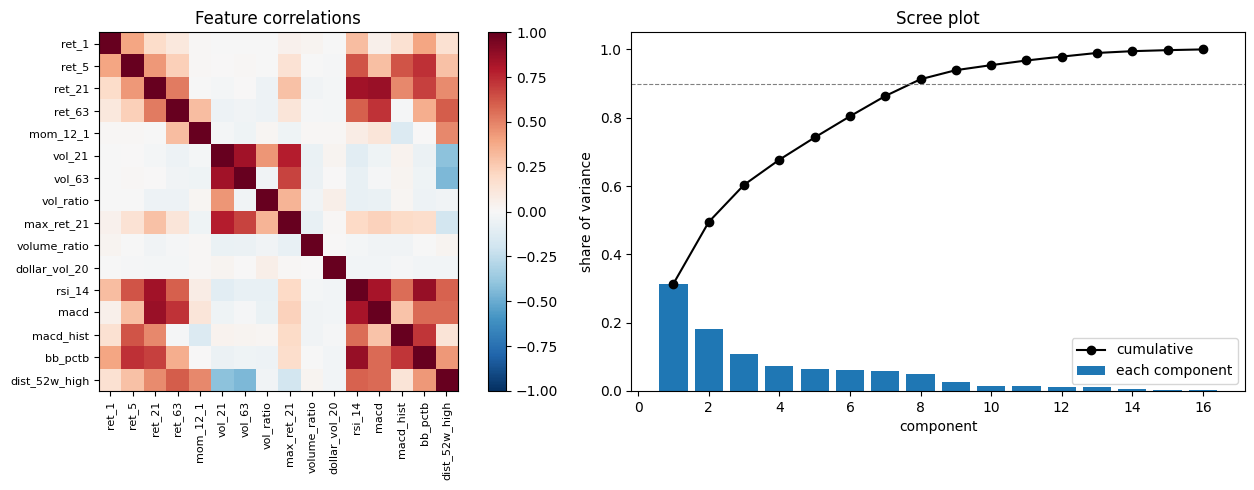

In [31]:
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    corr = panel[FEATURES].corr()
    im = ax[0].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax[0].set_xticks(range(len(FEATURES)), FEATURES, rotation=90, fontsize=8)
    ax[0].set_yticks(range(len(FEATURES)), FEATURES, fontsize=8)
    ax[0].set_title("Feature correlations")
    fig.colorbar(im, ax=ax[0], fraction=0.046)
    ax[1].bar(range(1, len(FEATURES) + 1), feat_var["explained"], label="each component")
    ax[1].plot(range(1, len(FEATURES) + 1), feat_var["cumulative"], "o-", color="black", label="cumulative")
    ax[1].axhline(0.9, color="grey", lw=0.8, ls="--")
    ax[1].set_xlabel("component"); ax[1].set_ylabel("share of variance"); ax[1].set_title("Scree plot")
    ax[1].legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "pca_features.png"), dpi=120)
    plt.show()
except ImportError:
    pass

### A2. Does a model on k components predict as well as one on all 16 features?
PCA is refit **inside each fold on training data only** (fitting it on all years would leak the
future into the components). To keep this quick, training uses every 5th day (labels don't overlap)
and a fixed C; `k = 16` is the same logistic model on all features, for comparison.

In [32]:
PCA_K_LIST = [1, 2, 3, 5, 8, 16]
PCA_C = 1.0


def pca_logit_scores(train, test, k, C=PCA_C):
    Xtr, Xte = X_of(train).astype("float64"), X_of(test).astype("float64")
    mu, sd = Xtr.mean(0), Xtr.std(0)
    Xtr, Xte = (Xtr - mu) / sd, (Xte - mu) / sd
    if k < Xtr.shape[1]:
        p = PCA(n_components=k).fit(Xtr)
        Xtr, Xte = p.transform(Xtr), p.transform(Xte)
    m = LogisticRegression(C=C, max_iter=500).fit(Xtr, train["y"].to_numpy())
    return m.predict_proba(Xte)[:, 1]


t0 = time.time()
pca_rows = []
for f in folds:
    train = panel[f["train_val"]]
    train = train[train["date_idx"] % HORIZON == 0]
    test = panel[f["test"]]
    for k in PCA_K_LIST:
        pca_rows.append({"test_year": f["test_year"], "k": k,
                         **evaluate(test, pca_logit_scores(train, test, k))})
pca_results = pd.DataFrame(pca_rows)
print(f"done in {time.time() - t0:.0f}s")
pca_results.groupby("k").agg(
    auc=("auc", "mean"), ic_mean=("ic_mean", "mean"),
    years_ic_positive=("ic_mean", lambda s: f"{(s > 0).sum()}/{len(s)}"),
    decile_spread_5d_bps=("top_minus_bottom_decile_5d_bps", "mean")).round(4)

done in 38s


,auc,ic_mean,years_ic_positive,decile_spread_5d_bps
k,,,,
1,0.5070,0.0168,17/22,32.1256
2,0.5075,0.0172,17/22,34.7179
3,0.5095,0.0200,18/22,30.6789
5,0.5113,0.0236,20/22,32.5457
8,0.5139,0.0286,21/22,35.4874
16,0.5151,0.0300,22/22,35.2401


### B. PCA on daily stock returns: the market's hidden structure

In [33]:
log_ret = np.log(wide["px"]).diff()
RET_WINDOW_START = str(log_ret.index.max() - pd.DateOffset(years=2))   # last two years of data
R = log_ret.loc[RET_WINDOW_START:]
R = R.loc[:, R.notna().mean() > 0.98].fillna(0.0)
R = R.loc[:, R.std() > 0]
Z = (R - R.mean()) / R.std()                                            # correlation-based PCA
pca_r = PCA().fit(Z.to_numpy())
ret_load = pd.DataFrame(pca_r.components_[:4].T, index=R.columns, columns=["PC1", "PC2", "PC3", "PC4"])
ret_load *= np.sign(ret_load.mean())                                    # orient each PC
ev_r = pca_r.explained_variance_ratio_
print(f"{R.shape[1]} stocks, {R.shape[0]} days from {R.index.min().date()} to {R.index.max().date()}")
print(f"PC1 (the market) explains {ev_r[0]:.1%} of daily return variation; "
      f"PCs 1-5: {ev_r[:5].sum():.1%}; PCs 1-10: {ev_r[:10].sum():.1%}")
print(f"stocks with a positive PC1 loading: {(ret_load['PC1'] > 0).mean():.0%} "
      "(all moving with the market)")

231 stocks, 499 days from 2024-09-03 to 2026-08-31
PC1 (the market) explains 22.1% of daily return variation; PCs 1-5: 43.1%; PCs 1-10: 51.5%
stocks with a positive PC1 loading: 100% (all moving with the market)


In [34]:
for pc in ["PC2", "PC3", "PC4"]:
    s = ret_load[pc].sort_values()
    print(f"{pc}  one end: {', '.join(s.index[:8])}\n     other end: {', '.join(s.index[-8:][::-1])}\n")

PC2  one end: LRCX, MU, NVDA, AMAT, KLAC, ETN, AVGO, AMD
     other end: DUK, SO, CL, KO, EXC, CB, PG, GIS

PC3  one end: BKNG, SHW, HD, ECL, TDG, EW, ADSK, MCO
     other end: XOM, COP, EOG, OXY, DVN, CVX, FANG, APA

PC4  one end: CAT, AMAT, LRCX, TXN, KLAC, PPG, NEE, CARR
     other end: NOW, CRM, ADP, ADSK, ACN, ROP, CRWD, DDOG



Nearest "peers" of a stock: stocks whose returns load most similarly on PCs 2–11
(PC1 is left out because every stock moves with the market). This is how Step 4 can learn
sector-like groups without a sector column.

In [35]:
PEER_OF = "AAPL" if "AAPL" in R.columns else R.columns[0]
F = pca_r.components_[1:11].T * np.sqrt(pca_r.explained_variance_[1:11])
F = F / np.linalg.norm(F, axis=1, keepdims=True)
peer_sim = pd.DataFrame(F @ F.T, index=R.columns, columns=R.columns)
print(f"Most similar stocks to {PEER_OF}:")
peer_sim[PEER_OF].drop(PEER_OF).nlargest(10).round(3)

Most similar stocks to AAPL:


Ticker
WBD     0.707
LVS     0.667
MGM     0.624
NKE     0.610
SBUX    0.590
MAR     0.533
BKNG    0.528
HLT     0.525
EXPE    0.504
AMZN    0.496
Name: AAPL, dtype: float64

How strongly does the whole market move together, year by year? (PC1 share of each year's returns.)
It jumps in crises, when "everything falls together"; that is when stock-picking signals have the
least room to work and the relative label matters most.

In [36]:
pc1_rows = []
for yr, g in log_ret.groupby(log_ret.index.year):
    g = g.loc[:, g.notna().mean() > 0.95].fillna(0.0)
    g = g.loc[:, g.std() > 0]
    if g.shape[1] < 50 or g.shape[0] < 100:
        continue
    eig = np.linalg.eigvalsh(np.corrcoef(g.to_numpy().T))
    pc1_rows.append({"year": yr, "pc1_share": eig[-1] / eig.sum(), "stocks": g.shape[1]})
pc1_by_year = pd.DataFrame(pc1_rows).set_index("year")
pc1_by_year.round(3).T

year,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
pc1_share,0.147,0.159,0.227,0.339,0.33,0.259,0.251,0.241,0.364,0.53,0.433,0.468,0.574,0.352,0.332,0.351,0.42,0.339,0.167,0.396,0.31,0.566,0.282,0.431,0.266,0.198,0.314,0.146
stocks,169.000,175.000,179.000,184.000,186.00,186.000,190.000,195.000,198.000,200.00,202.000,206.000,207.000,210.000,216.000,219.000,222.00,222.000,222.000,223.000,223.00,227.000,230.000,231.000,231.000,231.000,231.000,231.000


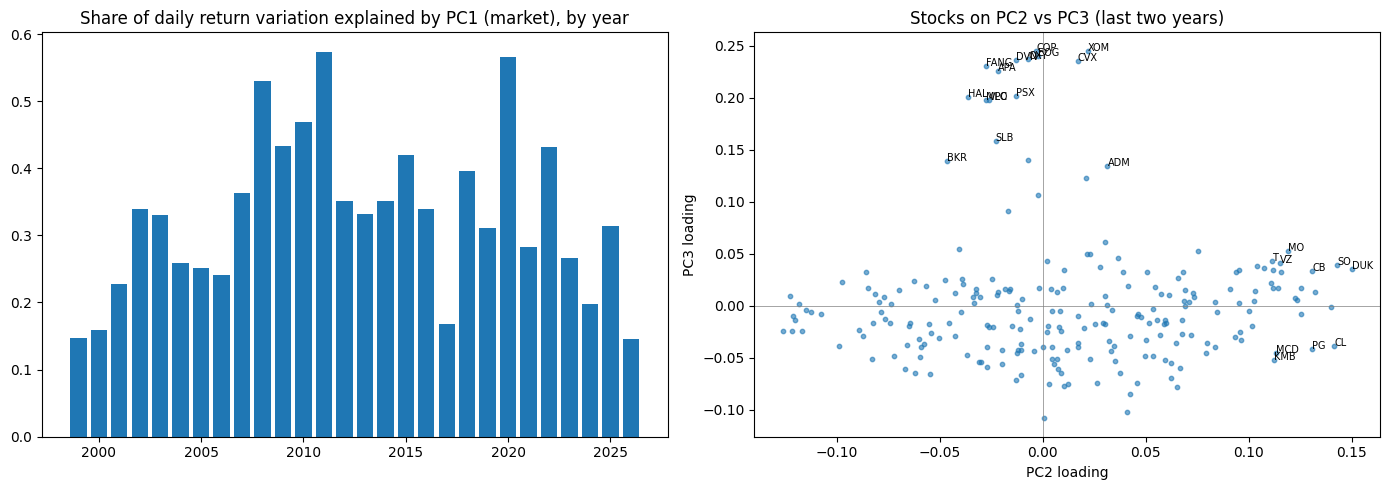

In [37]:
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    ax[0].bar(pc1_by_year.index, pc1_by_year["pc1_share"])
    ax[0].set_title("Share of daily return variation explained by PC1 (market), by year")
    x, y = ret_load["PC2"], ret_load["PC3"]
    ax[1].scatter(x, y, s=10, alpha=0.6)
    extreme = (x.abs() + y.abs()).nlargest(25).index
    for t in extreme:
        ax[1].annotate(t, (x[t], y[t]), fontsize=7)
    ax[1].axhline(0, color="grey", lw=0.5); ax[1].axvline(0, color="grey", lw=0.5)
    ax[1].set_xlabel("PC2 loading"); ax[1].set_ylabel("PC3 loading")
    ax[1].set_title(f"Stocks on PC2 vs PC3 (last two years)")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "pca_returns.png"), dpi=120)
    plt.show()
except ImportError:
    pass

pca_results.to_csv(os.path.join(OUT_DIR, "pca_logit_results_by_year.csv"), index=False)

## Step 7a — LightGBM (gradient-boosted trees)

LightGBM builds hundreds of small decision trees, each one correcting the errors of the previous ones.
Unlike logistic regression it can learn **non-linear effects** ("reversal only matters for volatile
stocks") and **interactions** between features, and it handles missing values natively.

Same walk-forward folds as the baselines, so the comparison is fair:
* train on years ≤ Y, use year Y+1 only to decide **when to stop adding trees** (early stopping on AUC),
* then refit on years ≤ Y+1 with that number of trees and predict year Y+2 (same as `REFIT_ON_TRAIN_VAL`).

Stock returns are mostly noise, so the settings are deliberately conservative: small learning rate,
large minimum leaf size, row/feature subsampling and L2 regularisation. This keeps the trees from
memorising noise.

In [38]:
import lightgbm as lgb

LGB_PARAMS = dict(
    objective="binary", metric="auc",
    learning_rate=0.05, num_leaves=31, max_depth=-1,
    min_child_samples=2000,          # every leaf must cover >= 2,000 stock-days
    feature_fraction=0.8, bagging_fraction=0.7, bagging_freq=1,
    lambda_l2=10.0, verbose=-1, seed=RANDOM_SEED, deterministic=True, force_row_wise=True,
)
LGB_MAX_ROUNDS = 1000
LGB_EARLY_STOP = 50


def lgb_data(df):
    return lgb.Dataset(df[FEATURES].to_numpy("float32"), label=df["y"].to_numpy(), free_raw_data=True)


def run_lightgbm(panel, folds, verbose=True):
    out_preds, out_rows, importances = [], [], []
    for f in folds:
        t0 = time.time()
        train, val, test = panel[f["train"]], panel[f["val"]], panel[f["test"]]
        # 1) pick the number of trees on the validation year
        booster = lgb.train(LGB_PARAMS, lgb_data(train), num_boost_round=LGB_MAX_ROUNDS,
                            valid_sets=[lgb_data(val)],
                            callbacks=[lgb.early_stopping(LGB_EARLY_STOP, verbose=False)])
        n_trees = max(booster.best_iteration, 10)
        val_auc = booster.best_score["valid_0"]["auc"]
        # 2) refit on train + validation with that many trees, predict the test year
        if REFIT_ON_TRAIN_VAL:
            booster = lgb.train(LGB_PARAMS, lgb_data(panel[f["train_val"]]), num_boost_round=n_trees)
        score = booster.predict(test[FEATURES].to_numpy("float32"), num_iteration=n_trees)
        p = test[["date", "ticker", "y", "fwd_ret"]].copy()
        p["prob_beat_median"] = score
        out_preds.append(p)
        out_rows.append({"test_year": f["test_year"], "model": "lightgbm", **evaluate(test, score)})
        importances.append(pd.Series(booster.feature_importance("gain"), index=FEATURES, name=f["test_year"]))
        if verbose:
            print(f"test {f['test_year']}: {n_trees:4d} trees, val AUC {val_auc:.4f}, "
                  f"test AUC {out_rows[-1]['auc']:.4f}  ({time.time() - t0:5.1f}s)")
    preds_lgb = pd.concat(out_preds, ignore_index=True)
    g = preds_lgb.groupby("date")["prob_beat_median"]
    preds_lgb["rank_pct"] = g.rank(pct=True)
    preds_lgb["predicted_y"] = (preds_lgb["prob_beat_median"] > g.transform("median")).astype(int)
    preds_lgb["correct"] = (preds_lgb["predicted_y"] == preds_lgb["y"]).astype(int)
    return preds_lgb, pd.DataFrame(out_rows), pd.concat(importances, axis=1)


t0 = time.time()
preds_lgb, lgb_results, lgb_importance = run_lightgbm(panel, folds)
print(f"LightGBM walk-forward done in {(time.time() - t0) / 60:.1f} min")

test 2005:   29 trees, val AUC 0.5268, test AUC 0.5201  (  2.1s)
test 2006:   64 trees, val AUC 0.5198, test AUC 0.5122  (  3.3s)
test 2007:   31 trees, val AUC 0.5130, test AUC 0.5168  (  2.5s)
test 2008:   50 trees, val AUC 0.5207, test AUC 0.5236  (  3.7s)
test 2009:   73 trees, val AUC 0.5211, test AUC 0.5318  (  4.9s)
test 2010:  157 trees, val AUC 0.5336, test AUC 0.5223  (  9.0s)
test 2011:   15 trees, val AUC 0.5240, test AUC 0.5119  (  2.9s)
test 2012:   69 trees, val AUC 0.5136, test AUC 0.5098  (  6.1s)
test 2013:  260 trees, val AUC 0.5144, test AUC 0.5228  ( 16.4s)
test 2014:   28 trees, val AUC 0.5269, test AUC 0.5213  (  4.4s)
test 2015:   39 trees, val AUC 0.5223, test AUC 0.5095  (  5.6s)
test 2016:  296 trees, val AUC 0.5176, test AUC 0.5144  ( 21.7s)
test 2017:   13 trees, val AUC 0.5210, test AUC 0.5171  (  4.2s)
test 2018:  113 trees, val AUC 0.5205, test AUC 0.5072  ( 12.0s)
test 2019:   10 trees, val AUC 0.5096, test AUC 0.5172  (  4.2s)
test 2020:   51 trees, va

### Ensemble: average of the two models' daily ranks
Logistic regression and LightGBM make partly different mistakes, so averaging their rankings
is a cheap way to get a steadier signal.

In [39]:
ens = preds[["date", "ticker", "y", "fwd_ret", "rank_pct"]].rename(columns={"rank_pct": "r_logit"}).merge(
    preds_lgb[["date", "ticker", "rank_pct"]].rename(columns={"rank_pct": "r_lgb"}), on=["date", "ticker"])
ens["prob_beat_median"] = 0.5 * ens["r_logit"] + 0.5 * ens["r_lgb"]
ens_rows = []
for f in folds:
    part = ens[ens["date"].dt.year == f["test_year"]]
    ens_rows.append({"test_year": f["test_year"], "model": "ensemble_logit_lgbm",
                     **evaluate(part, part["prob_beat_median"].to_numpy())})
g = ens.groupby("date")["prob_beat_median"]
ens["rank_pct"] = g.rank(pct=True)
ens["predicted_y"] = (ens["prob_beat_median"] > g.transform("median")).astype(int)
ens["correct"] = (ens["predicted_y"] == ens["y"]).astype(int)

### Results: all models, 22 out-of-sample test years

In [40]:
all_results = pd.concat([results, lgb_results, pd.DataFrame(ens_rows)], ignore_index=True)
summary_all = summarise(all_results)
summary_all

,accuracy,auc,ic_mean,ic_tstat_across_years,years_ic_positive,decile_spread_5d_bps
model,,,,,,
ensemble_logit_lgbm,0.511029,0.515921,0.032816,11.278921,22/22,39.360091
lightgbm,0.510441,0.515585,0.031483,11.052778,22/22,37.201351
logistic,0.510636,0.514894,0.029983,10.575740,22/22,37.249645
reversal_1w,0.506618,0.508987,0.019860,6.930337,20/22,25.095303
momentum_12_1,0.505258,0.507346,0.012380,1.883577,16/22,-3.581987
random,0.499417,0.499326,-0.002114,-1.990717,7/22,-5.093899
momentum_1m,0.497077,0.495127,-0.011861,-3.303768,4/22,-10.616000


In [41]:
by_year = all_results.pivot(index="test_year", columns="model", values="auc")
by_year["lgbm_minus_logit"] = by_year["lightgbm"] - by_year["logistic"]
print(f"LightGBM beats logistic AUC in {(by_year['lgbm_minus_logit'] > 0).sum()}/{len(by_year)} years")
by_year[["logistic", "lightgbm", "ensemble_logit_lgbm", "lgbm_minus_logit"]].round(4)

LightGBM beats logistic AUC in 13/22 years


model,logistic,lightgbm,ensemble_logit_lgbm,lgbm_minus_logit
test_year,,,,
2005,0.5160,0.5201,0.5185,0.0040
2006,0.5077,0.5122,0.5102,0.0045
2007,0.5135,0.5168,0.5158,0.0033
2008,0.5226,0.5236,0.5252,0.0010
2009,0.5221,0.5318,0.5289,0.0097
2010,0.5215,0.5223,0.5235,0.0008
2011,0.5158,0.5119,0.5134,-0.0039
2012,0.5047,0.5098,0.5075,0.0051
2013,0.5262,0.5228,0.5270,-0.0034


### Which features does LightGBM rely on?
"Gain" = total improvement in the training objective from splits on that feature, as a share of all
gain, averaged over the 22 yearly models. High gain means the feature is *used*, not that it causes
returns, and overlapping features (see the PCA section) share credit between them.

In [42]:
imp = lgb_importance.div(lgb_importance.sum(axis=0), axis=1)
imp_summary = pd.DataFrame({"mean_share": imp.mean(axis=1), "min_share": imp.min(axis=1),
                            "max_share": imp.max(axis=1)}).sort_values("mean_share", ascending=False)
imp_summary.round(3)

,mean_share,min_share,max_share
dollar_vol_20,0.140,0.103,0.221
mom_12_1,0.099,0.081,0.120
ret_5,0.096,0.037,0.157
rsi_14,0.076,0.036,0.195
ret_63,0.074,0.056,0.089
macd,0.072,0.052,0.086
dist_52w_high,0.064,0.040,0.082
vol_63,0.055,0.035,0.078
vol_21,0.053,0.037,0.062
macd_hist,0.050,0.028,0.064


### Backtest: logistic vs. LightGBM vs. ensemble (same rules: weekly, top/bottom 10%, 0.10% per trade)

In [43]:
bt_models = {"logistic": bt, "lightgbm": backtest(preds_lgb), "ensemble": backtest(ens)}
bt_compare = pd.DataFrame({
    (m, s): perf(b[s]) for m, b in bt_models.items() for s in ["long_short_gross", "long_short_net"]
}).T
bt_compare["avg_turnover"] = [bt_models[m]["turnover"].mean() for m, _ in bt_compare.index]
bt_compare.round(3)

annual_return  annual_vol  sharpe  max_drawdown  weeks_positive  avg_turnover
logistic long_short_gross          0.166       0.195   0.887        -0.429           0.582         0.635
         long_short_net            0.026       0.195   0.229        -0.554           0.521         0.635
lightgbm long_short_gross          0.186       0.169   1.097        -0.232           0.586         0.631
         long_short_net            0.045       0.169   0.344        -0.404           0.523         0.631
ensemble long_short_gross          0.184       0.181   1.022        -0.368           0.579         0.636
         long_short_net            0.041       0.181   0.314        -0.514           0.517         0.636

In [44]:
yearly_net = pd.DataFrame({m: b["long_short_net"].groupby(b.index.year).apply(lambda x: (1 + x).prod() - 1)
                           for m, b in bt_models.items()})
yearly_net.round(3)

,logistic,lightgbm,ensemble
date,,,
2005,0.074,0.185,0.188
2006,0.146,0.146,0.145
2007,-0.075,-0.002,-0.044
2008,0.543,0.502,0.551
2009,0.153,0.149,0.237
2010,0.099,0.102,0.061
2011,0.011,-0.006,-0.010
2012,-0.070,0.013,-0.022
2013,0.280,0.084,0.239


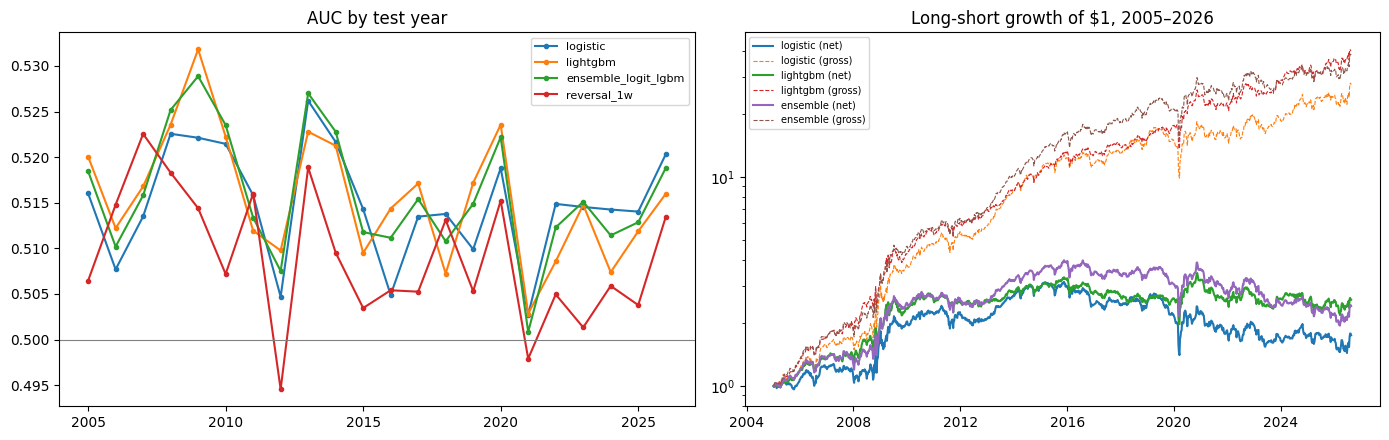

In [45]:
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
    for m in ["logistic", "lightgbm", "ensemble_logit_lgbm", "reversal_1w"]:
        g_ = all_results[all_results["model"] == m]
        ax[0].plot(g_["test_year"], g_["auc"], marker="o", ms=3, label=m)
    ax[0].axhline(0.5, color="grey", lw=0.8); ax[0].set_title("AUC by test year"); ax[0].legend(fontsize=8)
    for m, b in bt_models.items():
        ax[1].plot((1 + b["long_short_net"]).cumprod(), label=f"{m} (net)")
        ax[1].plot((1 + b["long_short_gross"]).cumprod(), ls="--", lw=0.8, label=f"{m} (gross)")
    ax[1].set_yscale("log"); ax[1].set_title("Long-short growth of $1, 2005–2026"); ax[1].legend(fontsize=7)
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "lightgbm_vs_logistic.png"), dpi=120)
    plt.show()
except ImportError:
    pass

all_results.to_csv(os.path.join(OUT_DIR, "all_models_results_by_year.csv"), index=False)
summary_all.to_csv(os.path.join(OUT_DIR, "all_models_summary.csv"))
preds_lgb.to_csv(os.path.join(OUT_DIR, "oos_predictions_lightgbm.csv.gz"), index=False)